# Robust phase estimation with bounded probability bias

This normal notebook reconstructs fresh-reset primitive circuits and replays every saved noisy-readout count batch. The conditional confidence bound uses a supplied additive probability promise and exact rational circular decisions. Experimental calibration, rotation synthesis, physical estimates and formal proof builds remain unexecuted.


In [1]:
from pathlib import Path
from fractions import Fraction
import hashlib, json, sys
root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
sys.path.insert(0, str(root / "src"))
from openquantum import robust_qpe as rq
records = root / "assets/generated/robust-qpe"
data = json.loads((records / "results.json").read_text())
manifest = json.loads((records / "manifest.json").read_text())
for name, expected in manifest["file_sha256"].items():
    assert hashlib.sha256((records / name).read_bytes()).hexdigest() == expected
assert data["environment"]["python"] == "3.12.14"
print("Producer source:", data["provenance"]["source_commit"])
print("Conditional robust radius:", data["confidence"]["phase_radius_exact"])
print("Every recorded outcome:", data["outcomes"])


Producer source: eca0cf40133993369f655dd0477cb6be7732369e
Conditional robust radius: 1/384
Every recorded outcome: {'within_radius': 8, 'miss': 0, 'inconclusive': 0}


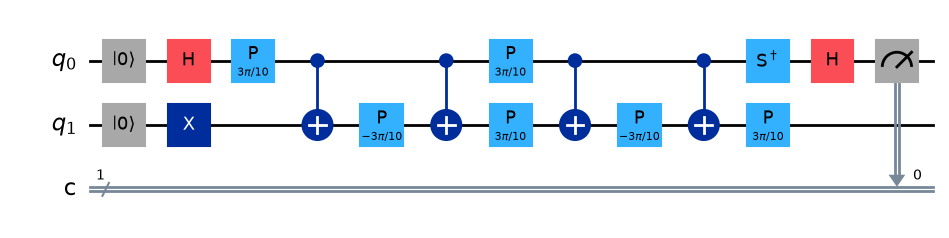

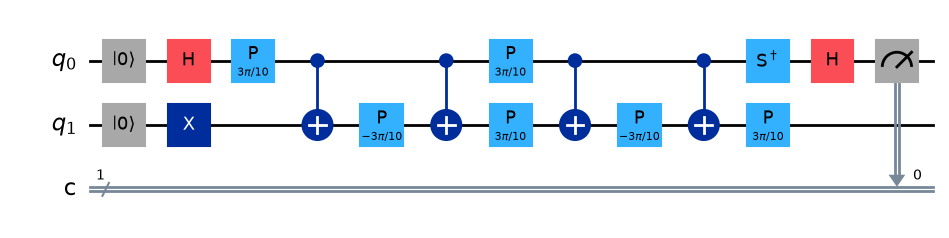

In [2]:
# This measured program includes every fresh reset and both literal calls.
circuit = rq.build_experiment(1, .3, 2, "sin")
assert circuit.count_ops()["reset"] == 2
assert circuit.count_ops()["measure"] == 1
rq.check_experiment(1, .3, 2, "sin")
circuit.draw(output="mpl", fold=32)


In [3]:
for run in data["runs"]:
    counts = [rq.FringeCounts(**record) for record in run["result"]["counts"]]
    replay = rq.recover_phase(counts, Fraction(data["parameters"]["additive_probability_bound_exact"]))
    assert replay == run["result"]
    print(run["case_id"], run["seed"], run["outcome"], replay["phase_estimate"])
print("No new sampling was performed by this notebook.")


phase-0 7 within_radius 0.30006101172136834
phase-0 19 within_radius 0.2998573896923
phase-1 7 within_radius 0.9948401638082215
phase-1 19 within_radius 0.9947907868429211
phase-2 7 within_radius 0.12526028360587627
phase-2 19 within_radius 0.125022710307786
phase-3 7 within_radius 0.4995365245830089
phase-3 19 within_radius 0.5
No new sampling was performed by this notebook.


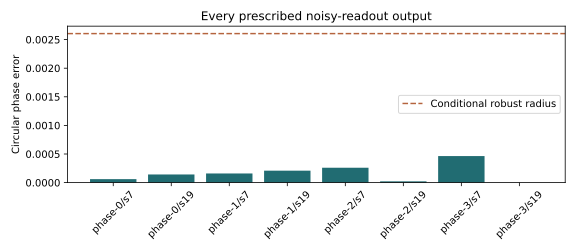

In [4]:
from IPython.display import SVG, display
display(SVG(filename=str(records / "recovery.svg")))


In [5]:
ledger = rq.protocol_ledger(1, data["parameters"]["levels"],
                            data["parameters"]["shots_per_fringe"], Fraction(1, 50))
assert ledger == data["common_per_output_ledger"]
print("Per output preparations/readouts:", ledger["complete_fresh_preparations"])
print("Per output literal controlled calls:", ledger["shot_weighted_controlled_U_calls"])
print("All represented study preparations:", data["whole_study_modeled_workload"]["fresh_preparations"])
print("Continuous rotations are unsynthesized; physical costing is planned.")


Per output preparations/readouts: 5376
Per output literal controlled calls: 56448
All represented study preparations: 43008
Continuous rotations are unsynthesized; physical costing is planned.


The confidence statement is uniform only within the supplied independent-Bernoulli/additive-bias model. The simulated readout confusion has rates `3/200` and `1/100` within the declared allowance `1/50`; the code does not learn that allowance from data. All outputs remain in the record. The nine-wire QASM is a materialized source/count example, with its dense check explicitly unexecuted.
